# 04 — HDFS: z-score and PCA detectors

Models trained on normal training blocks only. Thresholds: label-free (training percentiles) and
validation-tuned (best F1 on validation). Compared with baseline B4 (lookup table).
"Novel normal flagged": normal blocks whose count vector never appeared in training — the
generalisation test from Day 14.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Project root not found")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
OUT = ROOT / "data" / "processed"
RESULTS = ROOT / "experiments" / "results"

from backend.detection.evaluation.metrics import binary_metrics, ranking_metrics
from backend.detection.evaluation.thresholds import best_f1_threshold, percentile_threshold, predict
from backend.detection.models.pca import PCADetector
from backend.detection.models.statistical import ZScoreDetector

data = np.load(OUT / "hdfs_features.npz")
X_int, y = data["X"], data["y"]
X = X_int.astype(float)
train_normal, val, test = data["train_normal"], data["validation"], data["test"]

# Normal blocks whose exact count vector never appeared among training normals (B4's false positives)
keys = [row.tobytes() for row in X_int]
train_keys = {keys[i] for i in train_normal}
novel = np.array([k not in train_keys for k in keys])
for name, idx in (("validation", val), ("test", test)):
    print(f"{name:<10}: {int((novel[idx] & ~y[idx]).sum())} novel normal blocks")

validation: 3 novel normal blocks
test      : 77 novel normal blocks


In [2]:
models = {"z-score": ZScoreDetector(), "PCA": PCADetector(variance=0.95)}
scores = {}
for name, model in models.items():
    start = time.time()
    model.fit(X[train_normal])
    fitted = time.time()
    scores[name] = model.score(X)
    print(f"{name:<8} fit {fitted - start:5.2f} s   score 575k blocks {time.time() - fitted:5.2f} s")
print(f"PCA keeps {models['PCA'].n_components_} of {X.shape[1]} components (95% variance)")

z-score  fit  0.05 s   score 575k blocks  0.11 s
PCA      fit  0.23 s   score 575k blocks  0.16 s
PCA keeps 5 of 20 components (95% variance)


In [3]:
rows = []
for name, s in scores.items():
    for part, idx in (("validation", val), ("test", test)):
        rows.append({"model": name, "split": part, **{k: round(v, 4) for k, v in ranking_metrics(y[idx], s[idx]).items()}})
display(pd.DataFrame(rows))

,model,split,pr_auc,roc_auc
0,z-score,validation,0.5471,0.9439
1,z-score,test,0.7562,0.8738
2,PCA,validation,0.9951,0.9999
3,PCA,test,0.9947,0.9999


In [4]:
rows = []
for name, s in scores.items():
    thresholds = {
        "label-free p99.9": percentile_threshold(s[train_normal], 99.9),
        "label-free max": percentile_threshold(s[train_normal], 100),
        "validation-tuned": best_f1_threshold(y[val], s[val])[0],
    }
    for threshold_name, threshold in thresholds.items():
        flagged = predict(s, threshold)
        for part, idx in (("validation", val), ("test", test)):
            m = binary_metrics(y[idx], flagged[idx])
            novel_normal = idx[novel[idx] & ~y[idx]]
            rows.append({
                "model": name, "threshold": threshold_name, "value": round(threshold, 4), "split": part,
                "precision": round(m.precision, 4), "recall": round(m.recall, 4), "f1": round(m.f1, 4),
                "fp": m.fp, "fn": m.fn,
                "novel_normal_flagged": f"{int(flagged[novel_normal].sum())}/{len(novel_normal)}",
            })

results = pd.DataFrame(rows)
display(results[results["split"] == "validation"])
display(results[results["split"] == "test"])

baselines = pd.read_csv(RESULTS / "hdfs_baselines.csv")
print("Reference, baseline B4 (lookup table):")
display(baselines[baselines["baseline"].str.startswith("B4")])

,model,threshold,value,split,precision,recall,f1,fp,fn,novel_normal_flagged
0,z-score,label-free p99.9,10.0959,validation,0.2411,0.0067,0.0131,85,3974,2/3
2,z-score,label-free max,69.4528,validation,0.0000,0.0000,0.0000,0,4001,0/3
4,z-score,validation-tuned,3.9826,validation,0.8464,0.4874,0.6186,354,2051,3/3
6,PCA,label-free p99.9,2.2020,validation,0.9986,0.8930,0.9429,5,428,1/3
8,PCA,label-free max,208.1171,validation,0.9615,0.0062,0.0124,1,3976,1/3
10,PCA,validation-tuned,0.0744,validation,0.9732,1.0000,0.9864,110,0,3/3


,model,threshold,value,split,precision,recall,f1,fp,fn,novel_normal_flagged
1,z-score,label-free p99.9,10.0959,test,0.2857,0.0012,0.0024,5,1677,0/77
3,z-score,label-free max,69.4528,test,0.0000,0.0000,0.0000,0,1679,0/77
5,z-score,validation-tuned,3.9826,test,0.7831,0.7653,0.7741,356,394,0/77
7,PCA,label-free p99.9,2.2020,test,0.9524,0.9774,0.9647,82,38,77/77
9,PCA,label-free max,208.1171,test,1.0000,0.0012,0.0024,0,1677,0/77
11,PCA,validation-tuned,0.0744,test,0.9230,1.0000,0.9600,140,0,77/77


Reference, baseline B4 (lookup table):


,baseline,split,precision,recall,f1,fpr,tp,fp,fn
6,B4 count vector never seen in training (lookup...,validation,0.9993,1.0,0.9996,0.00003,4001,3,0
7,B4 count vector never seen in training (lookup...,test,0.9562,1.0,0.9776,0.00068,1679,77,0


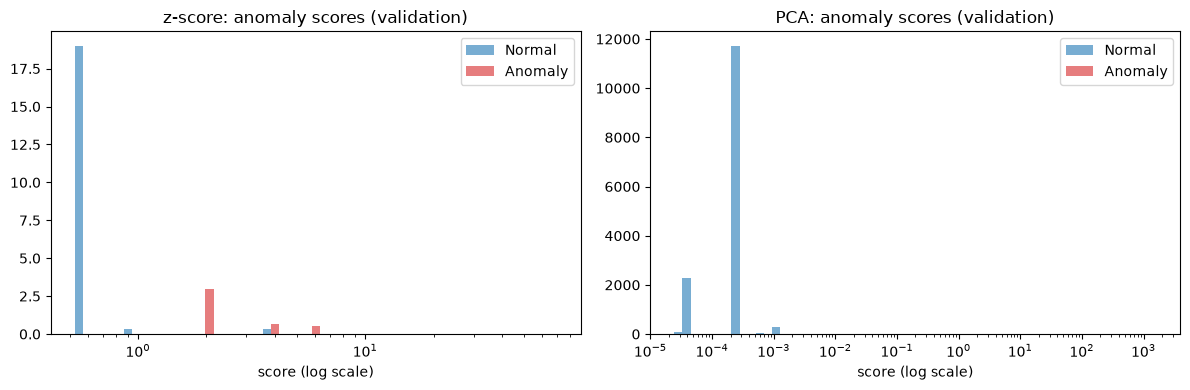

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, s) in zip(axes, scores.items()):
    values = s[val]
    bins = np.logspace(np.log10(max(values.min(), 1e-6)), np.log10(values.max() + 1e-6), 60)
    ax.hist(values[~y[val]], bins=bins, alpha=0.6, label="Normal", density=True)
    ax.hist(values[y[val]], bins=bins, alpha=0.6, label="Anomaly", density=True, color="tab:red")
    ax.set_xscale("log")
    ax.set_title(f"{name}: anomaly scores (validation)")
    ax.set_xlabel("score (log scale)")
    ax.legend()
plt.tight_layout()
plt.show()

In [6]:
results.to_csv(RESULTS / "hdfs_statistical_pca.csv", index=False)
print("Saved experiments/results/hdfs_statistical_pca.csv")

Saved experiments/results/hdfs_statistical_pca.csv


## Findings
- Ranking (threshold-free): PCA PR-AUC 0.995 (val and test), ROC-AUC 0.9999; z-score PR-AUC 0.547 / 0.756.
- PCA keeps 5 of 20 components: normal behaviour lies in a 5-dimensional subspace.
- z-score looks at one feature at a time and fails; HDFS anomalies break relationships between counts
  (e.g. a write starts but never completes), which PCA captures.
- Best test result: PCA with label-free p99.9 threshold: precision 0.952, recall 0.977, F1 0.965 (82 FP).
  Validation-tuned threshold was worse on test (F1 0.960, 140 FP): it fits validation's anomaly mix,
  which drifts over time.
- "Label-free max" fails for both models: training normals contain a few extreme blocks, so the maximum is
  far too strict. High percentiles are robust to such outliers.
- B4 lookup table: F1 0.978. PCA nearly matches it and adds a graded score, but flags all 77 novel normal
  blocks too: these blocks genuinely break normal patterns (possible label noise; examine in error analysis).